<a href="https://colab.research.google.com/github/RiccardoNesca/astrostatistics_bicocca_2026/blob/main/working/ES8_Transient_signal_part_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Tasks

**Remember this is a real research example, not an exam! You're welcome (and encouraged actually!) to use all the tutorials/answers/hack you find online!**






In [61]:
import numpy as np
import matplotlib.pyplot as plt

1) Read in `solutions/transient.npy`. This is a (100 x 3) numpy array, containing some time-series measurements from a transient phenomenon. The first column is time (arbitrary units), the second column is the flux (arbitrary units), and the third column are homoescedastic measurement uncertainties on the flux. Plot this data with the uncertainties.

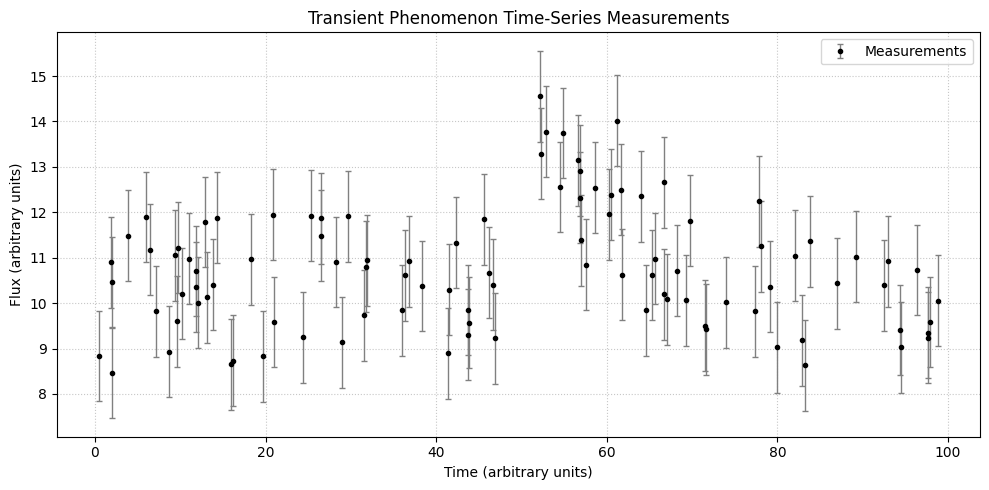

In [62]:
data = np.load('transient.npy')
time = np.array(data[:, 0])
flux = np.array(data[:, 1])
sigma = np.array(data[:, 2]) #gaussian homoschedastic

#plot
fig, ax = plt.subplots(figsize=(10, 5))

plt.plot()
ax.errorbar(
    time,
    flux,
    yerr=sigma,
    fmt='.',
    color='black',
    ecolor='gray',
    elinewidth=1,
    capsize=2,
    label='Measurements'
)

ax.set_xlabel('Time (arbitrary units)')
ax.set_ylabel('Flux (arbitrary units)')
ax.set_title('Transient Phenomenon Time-Series Measurements')
ax.grid(True, linestyle=':', alpha=0.7)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

2) One possible model for this data is a sharp burst with an exponential tail rising above a nominal background level. This model can be described as:

$y = b$, for $t<t_0$


$y = b + A\exp[-\alpha(t-t_0)]$, for $t\geq t_0$

where $b$ is the background amplitude, $A$ is the burst amplitude, $t_0$ is the burst epoch, and $\alpha$ encodes how rapidly the burst dies off.

Code this burst model, and code a likelihood function for this data with the burst model. *Hint: This is similar in spirit to the likelihood when fitting polynomials to data, except now $x$ is time, and the polynomial model is now the burst model.

3) Using one of the MCMC sampler that we looked at in class (`emcee`, `pymc`), perform a Bayesian analysis that recovers an MCMC chain of posterior probability samples for the joint parameter space of $\{b,A,t_0,\alpha\}$. You must decide on how many samples are appropriate for running your MCMC. For your priors, make them $b\in \mathrm{Uniform}[0,50]$, $A\in \mathrm{Uniform}[0,50]$, $t_0\in \mathrm{Uniform}[0,100]$, and $\ln\alpha\in \mathrm{Uniform}[-5,5]$ (careful: uniform in $\ln\alpha$, not $\alpha$).

In [63]:
def model(t,theta):
#model definition 4-D
    b,A,t0,alpha=theta
    modell = np.where(t < t0, b, b + A*np.exp(-alpha*(t-t0)))
    return modell

def logL(y,t,theta,sigma):
#likelihood
  return np.sum(((y-model(t,theta))**2)/(-2*sigma**2))

def logPrior(theta):
    b,A,t0,alpha=theta
    if  0 <b <50 and 0< A < 50 and 0 < t0 < 100 and  np.e**-5 <alpha<np.e**5:
      return 0+0+0-np.log(alpha) # if in bound return 1*1*1*1/alpha (1/alpha normalizzation) but here we applied the ln because emcee want the logposterior
    return -np.inf



def logPosterior(theta, y, t, sigma): #this parameter disposition is the one imposed by emcee
  return logL(y,t,theta,sigma)+logPrior(theta)



Theta initialization with frequentist approach



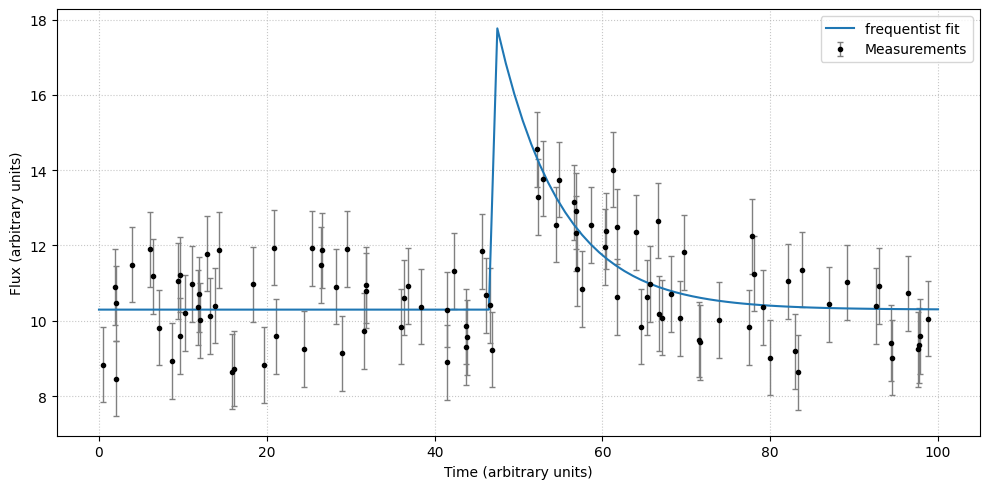

In [83]:
from scipy import optimize

p0 = [5.0, 10.0, 50.0, 0.1]
lower_bounds = [0.0, 0.0, 0.0, np.exp(-5)]
upper_bounds = [50.0, 50.0, 100.0, np.exp(5)]


#fast optimizzation
popt, pcov = optimize.curve_fit(
    f=lambda time, *theta: model(time, theta), #lambda function to preserve the model parameter definition (theta instead of 4 parameters)
    xdata=time,
    ydata=flux,
    p0=p0,
    sigma=sigma,
    bounds=(lower_bounds, upper_bounds)
  )

guessing_theta= np.array(popt)


#plot
fig, ax = plt.subplots(figsize=(10, 5))

plt.plot()
ax.errorbar(
    time,
    flux,
    yerr=sigma,
    fmt='.',
    color='black',
    ecolor='gray',
    elinewidth=1,
    capsize=2,
    label='Measurements'
)

ax.set_xlabel('Time (arbitrary units)')
ax.set_ylabel('Flux (arbitrary units)')
ax.grid(True, linestyle=':', alpha=0.7)
ax.legend(loc='upper right')
plt.tight_layout()
#plot with guessing parameters
tgrid=np.linspace(0,100,100)
ygrid=model(tgrid,guessing_theta)
plt.plot(tgrid,ygrid,label='frequentist fit')
plt.legend()
plt.show()

RUNNING emcee

(10000, 16, 4)
acceptance: 0.5322437499999999


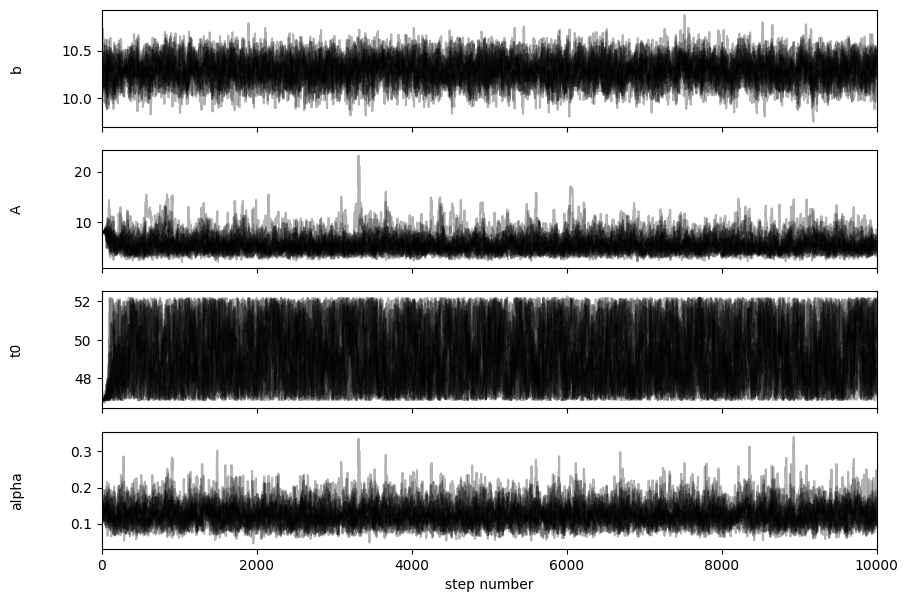

In [120]:
import emcee
#import time as tm


labels = ['b','A','t0','alpha']
ndim = 4  # number of parameters in the model
nwalkers = ndim*4  # number of MCMC walkers #optimal (2-4)*ndim
nsteps = 10000  # number of MCMC steps to take **for each walker**
burn= 3000
# initialize theta
np.random.seed(0)
starting_guesses = guessing_theta+1e-3*np.random.randn(nwalkers, ndim) #4d parameter space



# the function call where all the work happens:
sampler = emcee.EnsembleSampler(nwalkers, ndim, logPosterior,args=[flux,time, sigma])
#elapsed=tm.time()
trace_emcee=sampler.run_mcmc(starting_guesses, nsteps)
#print(time.time()-elapsed)


#plot raw chain
samples = sampler.get_chain()
print(samples.shape)

fig, axes = plt.subplots(4, figsize=(10, 7), sharex=True)
labels = ["b","A",'t0','alpha']
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:,:,i],'k', alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)
axes[-1].set_xlabel("step number");

acceptance=np.mean(sampler.acceptance_fraction)
print("acceptance:", acceptance) # should be between 20%-50%
#explore a small region of the parameter space


4) Perform an appropriate check to burn-in your chain, and thin the chain by selecting only points every auto-correlation length. If you are left with a small number of samples after thinning then you may need to run your MCMC for longer in (3).

**arviz_stats.rhat**

The rank normalized R-hat diagnostic tests for lack of convergence by comparing the variance between multiple chains to the variance within each chain. If convergence has been achieved, the between-chain and within-chain variances should be identical.

In [121]:
#Check with Gelman-Rubin pre burning
import arviz as az

idata = az.from_emcee(sampler,var_names=labels)
print('------R STATISTIC-------')
print( az.rhat(idata).data_vars)


------R STATISTIC-------
Data variables:
    A        float64 8B 1.007
    alpha    float64 8B 1.005
    b        float64 8B 1.008
    t0       float64 8B 1.007


R-Test already good (R<1.05)

In [122]:
#R-test after thinning and burning
tau = sampler.get_autocorr_time()
burn = int(3 * np.max(tau))
thin_step = int(np.max(tau))


sample_refined = idata.sel(draw=slice(burn, None, thin_step))

print('------R STATISTIC-------')
print(az.rhat(sample_refined).data_vars)
print('------EFFECTIVE SEMPLE SIZE-------')
print(az.ess(sample_refined).data_vars)




------R STATISTIC-------
Data variables:
    A        float64 8B 1.0
    alpha    float64 8B 0.9999
    b        float64 8B 1.004
    t0       float64 8B 0.9995
------EFFECTIVE SEMPLE SIZE-------
Data variables:
    A        float64 8B 1.619e+03
    alpha    float64 8B 1.648e+03
    b        float64 8B 1.69e+03
    t0       float64 8B 1.536e+03


The values used for thinning and burning preserve R-test, non autocorrelation principle and leave enough simple size

5) Make a corner plot of the $4$-D parameter space, with labels, $[68,95]\%$ credible levels and quantiles, and titles.

(2000, 4)


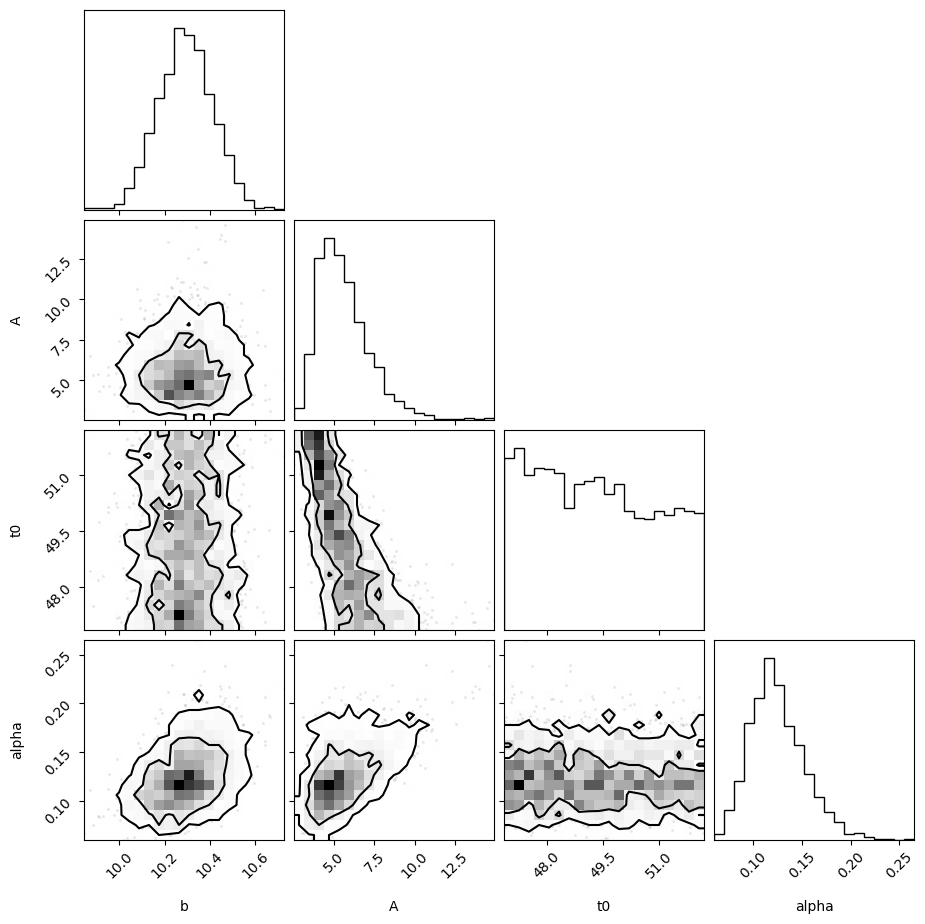

In [124]:
import corner

#flattening on the chains
flat_samples = sampler.get_chain(discard=burn, thin=thin_step, flat=True) #easy to work with emcee values then az
print(flat_samples.shape)

#plot with corner
fig = corner.corner(
    flat_samples, labels=labels, levels=[0.68,0.95],truths=[1,1,1,1]
);

6) Now choose $100$ samples randomly from your burned, thinned chain and plot the $100$ corresponding burst time-series on a figure along with the original data. You may want to choose a transparency for these $100$ burst curves that allows you to see everything nicely. These are showing the posterior spread of model solutions that are consistent with the data.

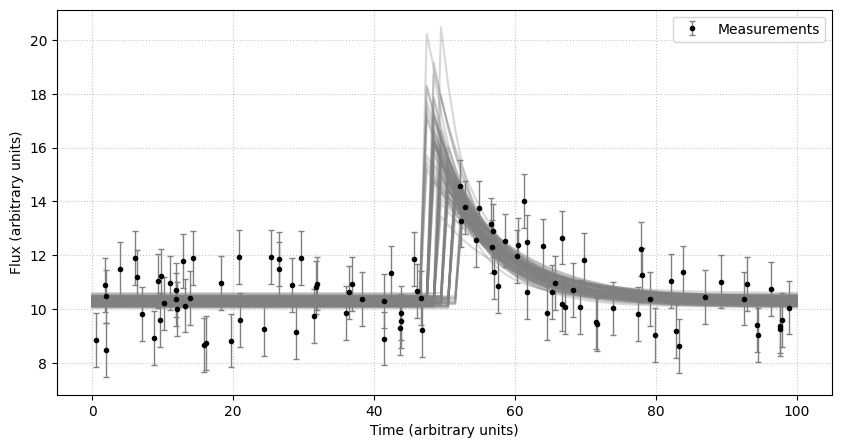

In [143]:
random_samples=flat_samples[np.random.choice(len(flat_samples),size=100)]
#plot
fig, ax = plt.subplots(figsize=(10, 5))

plt.plot()
ax.errorbar(
    time,
    flux,
    yerr=sigma,
    fmt='.',
    color='black',
    ecolor='gray',
    elinewidth=1,
    capsize=2,
    label='Measurements'
)

ax.set_xlabel('Time (arbitrary units)')
ax.set_ylabel('Flux (arbitrary units)')
ax.grid(True, linestyle=':', alpha=0.7)
ax.legend(loc='upper right')
tgrid=np.linspace(0,100,100)
for i in range(100):
  random_theta=[random_samples[i][0],random_samples[i][1],random_samples[i][2],random_samples[i][3]]
  ygrid=model(tgrid,random_theta)
  plt.plot(tgrid,ygrid,alpha=0.3,c='grey')


7) For each parameter, find the median and 90% credible region of the marginalized distribution and quote results as, for instance, $t_0=X^{+Y}_{-Z}$

In [156]:
print('---------PARAMETER MEDIAN AND CREDIBLE REGION------------')
for i,label in zip (range(4),labels):
  median=np.median(flat_samples[:,i])
  low_bound=np.percentile(flat_samples[:,i],5)
  high_bound=np.percentile(flat_samples[:,i],95)
  print(label)
  print(f"median = {median:.4f}")
  print(f'credible region 90% : {low_bound:.4f}-{high_bound:.4f}')

---------PARAMETER MEDIAN AND CREDIBLE REGION------------
b
median = 10.2907
credible region 90% : 10.0938-10.4858
A
median = 5.3116
credible region 90% : 3.5911-8.6120
t0
median = 49.2247
credible region 90% : 47.0828-51.8850
alpha
median = 0.1215
credible region 90% : 0.0843-0.1758
